In [2]:
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

from pandas.plotting import parallel_coordinates
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = [11, 8]
RANDOM_STATE = 42

In [3]:
URL = "https://media.githubusercontent.com/media/vxuv/ratemyprofessor-dataset/main/reviews.csv"
df = pd.read_csv(URL, nrows=10000, on_bad_lines="skip")
print(df.shape)
display(df.head())

(10000, 16)


,id,first_name,last_name,title,quality,difficulty,tags,comment,date,emotional_label,class,for_credit,attendence,would_take_again,grade,textbook
0,2000000,Kimberly,Rule,Professor in the Criminal Justice department a...,5.0,5.0,['Gives good feedback'],<TEACHER>'s classes are great! I learned so mu...,"May 6th, 2021",awesome,FRSC510,True,Mandatory,True,A,True
1,2000000,Kimberly,Rule,Professor in the Criminal Justice department a...,5.0,5.0,[],She is super nice! She tends to talk to the cl...,"Apr 21st, 2015",awesome,FRSC201,True,NaN,NaN,NaN,False
2,2000000,Kimberly,Rule,Professor in the Criminal Justice department a...,5.0,5.0,[],"AKA <TEACHER> Carisi. Yes, she speaks as if i...","Apr 13th, 2015",awesome,FRSC201,True,NaN,NaN,NaN,False
3,2000002,Rusty,Spell,Professor in the English department at Alabama...,5.0,5.0,['Gives good feedback'],He was a really good professor. Always let us ...,"Jan 26th, 2022",awesome,ENG131,True,NaN,True,A,True
4,2000002,Rusty,Spell,Professor in the English department at Alabama...,4.0,4.0,['Tough grader'],"Great teacher, willing to help . All you have ...","Jan 13th, 2022",awesome,ENG131,True,NaN,True,NaN,NaN


In [4]:
df.columns.to_list()

['id',
 'first_name',
 'last_name',
 'title',
 'quality',
 'difficulty',
 'tags',
 'comment',
 'date',
 'emotional_label',
 'class',
 'for_credit',
 'attendence',
 'would_take_again',
 'grade',
 'textbook']

In [5]:
db = df[['difficulty', 'would_take_again', 'for_credit']].copy()

display(db)

,difficulty,would_take_again,for_credit
0,5.0,True,True
1,5.0,NaN,True
2,5.0,NaN,True
3,5.0,True,True
4,4.0,True,True
...,...,...,...
9995,4.0,True,True
9996,4.0,True,True
9997,4.0,True,True
9998,2.0,False,True


In [6]:
print(db.isna().sum())
print()
print(round((db.isna().sum() / len(db)) * 100, 2))

difficulty             0
would_take_again    3500
for_credit           312
dtype: int64

difficulty           0.00
would_take_again    35.00
for_credit           3.12
dtype: float64


In [7]:
db = db.dropna()

def to_binary(value):
    value = str(value).strip().lower()
    if value in ["yes", "true", "1"]:
        return 1
    if value in ["no", "false", "0"]:
        return 0
    return np.nan

for column in ["would_take_again", "for_credit"]:
    db[column] = db[column].apply(to_binary)

data = db.dropna().copy()

print(len(data))
display(data.head())
print(data.dtypes)
display(data.describe())

6318


,difficulty,would_take_again,for_credit
0,5.0,1,1
3,5.0,1,1
4,4.0,1,1
5,5.0,1,1
6,4.0,0,1


difficulty          float64
would_take_again      int64
for_credit            int64
dtype: object


,difficulty,would_take_again,for_credit
count,6318.000000,6318.000000,6318.0
mean,3.919911,0.742482,1.0
std,1.452399,0.437302,0.0
min,1.000000,0.000000,1.0
25%,3.000000,0.000000,1.0
50%,5.000000,1.000000,1.0
75%,5.000000,1.000000,1.0
max,5.000000,1.000000,1.0


In [8]:
from sklearn.cluster import KMeans
kmeans = KMeans(
    n_clusters=3,       # Количество кластеров
    init='k-means++',   # Метод инициализации
    n_init=10,          # Количество запусков
    max_iter=300,       # Максимальное число итераций
    tol=1e-4,           # Допуск для сходимости
    random_state=42     # Для воспроизводимости
)

X = data[['difficulty', 'would_take_again', 'for_credit']].astype(float)
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 3)","[[1.3

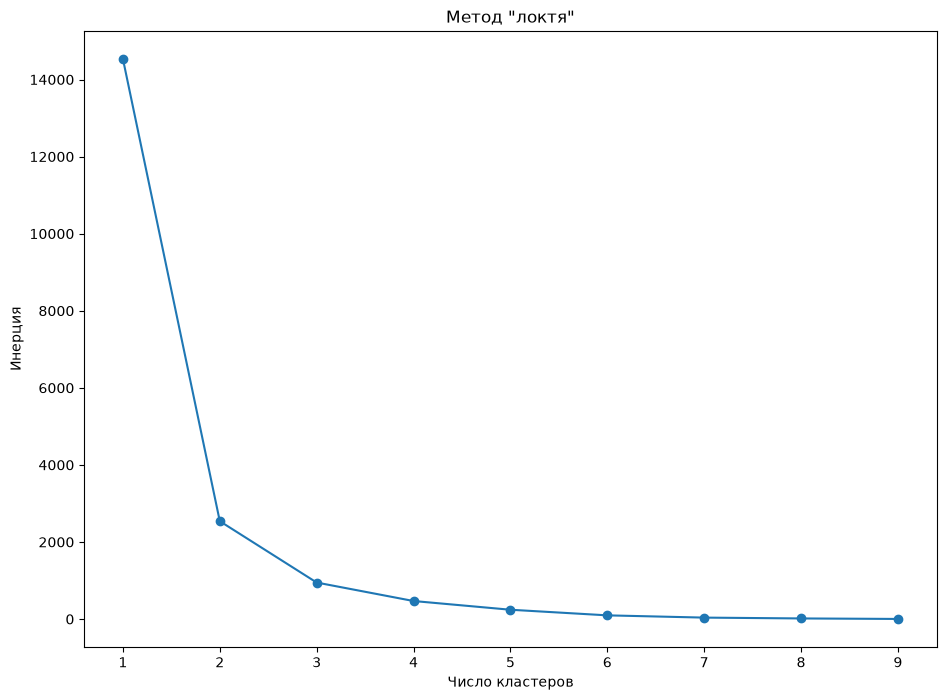

In [9]:
inertia = []
for k in range(1, 10):
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 10), inertia, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('Инерция')
plt.title('Метод "локтя"')
plt.show()

Среднее значение силуэта: 0.83


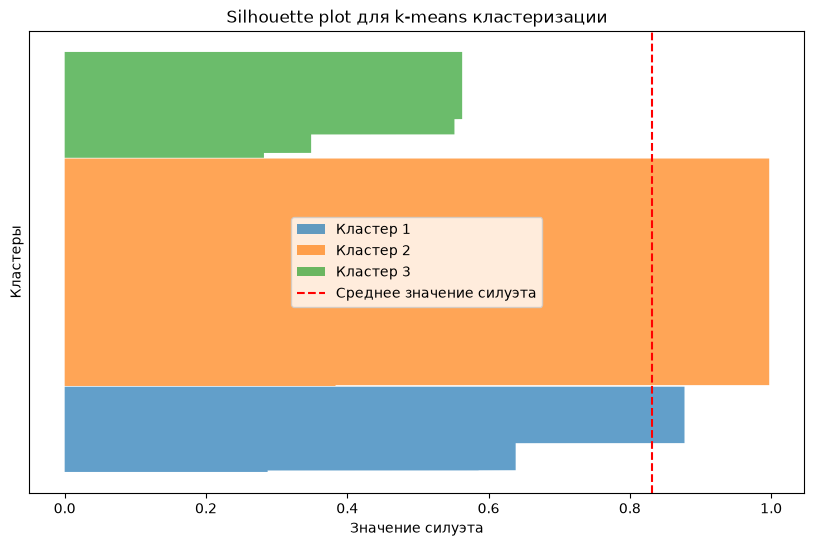

In [10]:
from sklearn.metrics import silhouette_samples, silhouette_score


# Кластеризация с помощью k-means
kmeans = KMeans(n_clusters=3, init='k-means++', n_init=10, max_iter=300, random_state=42)
labels = kmeans.fit_predict(X)

# Вычисление значений силуэта для каждого объекта
silhouette_vals = silhouette_samples(X, labels)

# Среднее значение силуэта
silhouette_avg = silhouette_score(X, labels)
print(f"Среднее значение силуэта: {silhouette_avg:.2f}")

# Построение графика силуэта
plt.figure(figsize=(10, 6))
y_lower = 10  # Отступ для визуализации

# Перебираем кластеры
for i in range(3):
    # Собираем значения силуэта для текущего кластера
    cluster_silhouette_vals = silhouette_vals[labels == i]
    cluster_silhouette_vals.sort()

    # Размер текущего кластера
    y_upper = y_lower + cluster_silhouette_vals.shape[0]

    # Закрашиваем область для текущего кластера
    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_silhouette_vals,
        alpha=0.7,
        label=f"Кластер {i+1}"
    )

    # Обновляем отступ для следующего кластера
    y_lower = y_upper + 10

# Среднее значение силуэта (вертикальная линия)
plt.axvline(x=silhouette_avg, color="red", linestyle="--", label="Среднее значение силуэта")

# Настройка графика
plt.title("Silhouette plot для k-means кластеризации")
plt.xlabel("Значение силуэта")
plt.ylabel("Кластеры")
plt.yticks([])  # Убираем метки на оси Y
plt.legend()
plt.show()

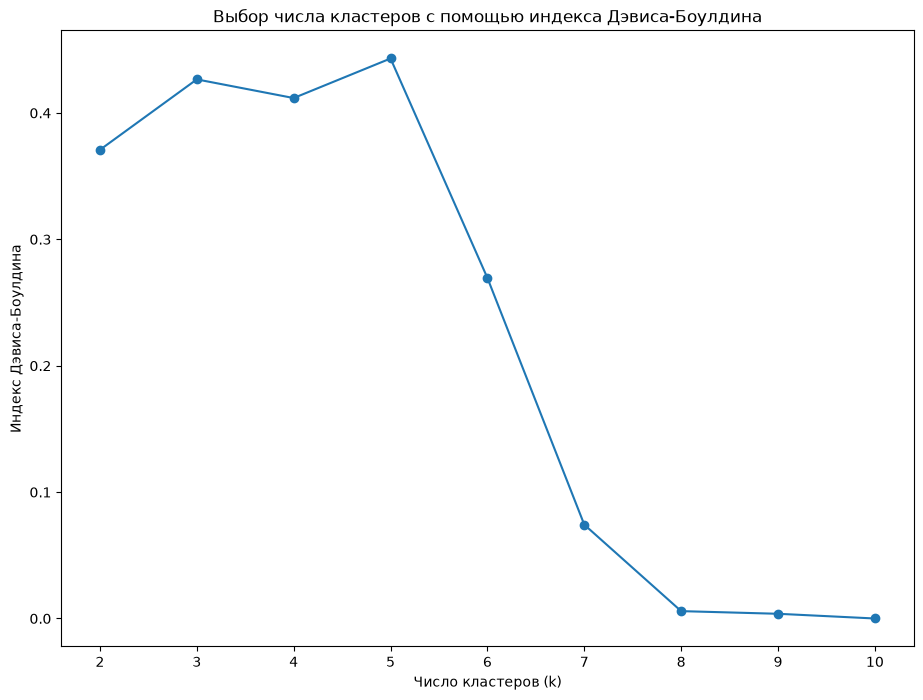

Индекс Дэвиса-Боулдина: 0.00


In [11]:
from sklearn.metrics import davies_bouldin_score

dbi_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)
    dbi = davies_bouldin_score(X, labels)
    dbi_scores.append(dbi)

plt.plot(k_values, dbi_scores, marker='o')
plt.xlabel('Число кластеров (k)')
plt.ylabel('Индекс Дэвиса-Боулдина')
plt.title('Выбор числа кластеров с помощью индекса Дэвиса-Боулдина')
plt.show()


from sklearn.metrics import davies_bouldin_score

dbi = davies_bouldin_score(X, labels)
print(f"Индекс Дэвиса-Боулдина: {dbi:.2f}")

График показывает наименьшее значение индекс Дэвиса-Боулдина 8-10.

Среднее значение силуэта: 1.00


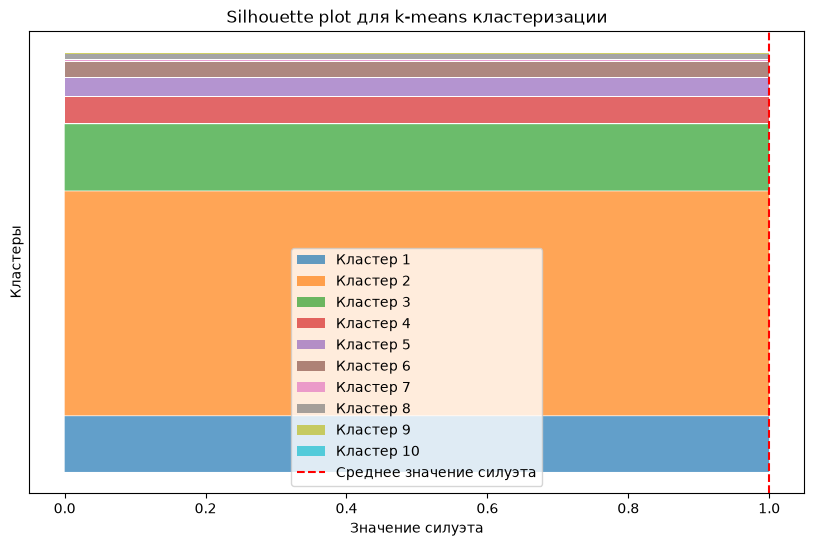

In [12]:
from sklearn.metrics import silhouette_samples, silhouette_score


# Кластеризация с помощью k-means
kmeans = KMeans(n_clusters=10, init='k-means++', n_init=10, max_iter=300, random_state=42)
labels = kmeans.fit_predict(X)

# Вычисление значений силуэта для каждого объекта
silhouette_vals = silhouette_samples(X, labels)

# Среднее значение силуэта
silhouette_avg = silhouette_score(X, labels)
print(f"Среднее значение силуэта: {silhouette_avg:.2f}")

# Построение графика силуэта
plt.figure(figsize=(10, 6))
y_lower = 10  # Отступ для визуализации

# Перебираем кластеры
for i in range(10):
    # Собираем значения силуэта для текущего кластера
    cluster_silhouette_vals = silhouette_vals[labels == i]
    cluster_silhouette_vals.sort()

    # Размер текущего кластера
    y_upper = y_lower + cluster_silhouette_vals.shape[0]

    # Закрашиваем область для текущего кластера
    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_silhouette_vals,
        alpha=0.7,
        label=f"Кластер {i+1}"
    )

    # Обновляем отступ для следующего кластера
    y_lower = y_upper + 10

# Среднее значение силуэта (вертикальная линия)
plt.axvline(x=silhouette_avg, color="red", linestyle="--", label="Среднее значение силуэта")

# Настройка графика
plt.title("Silhouette plot для k-means кластеризации")
plt.xlabel("Значение силуэта")
plt.ylabel("Кластеры")
plt.yticks([])  # Убираем метки на оси Y
plt.legend()
plt.show()

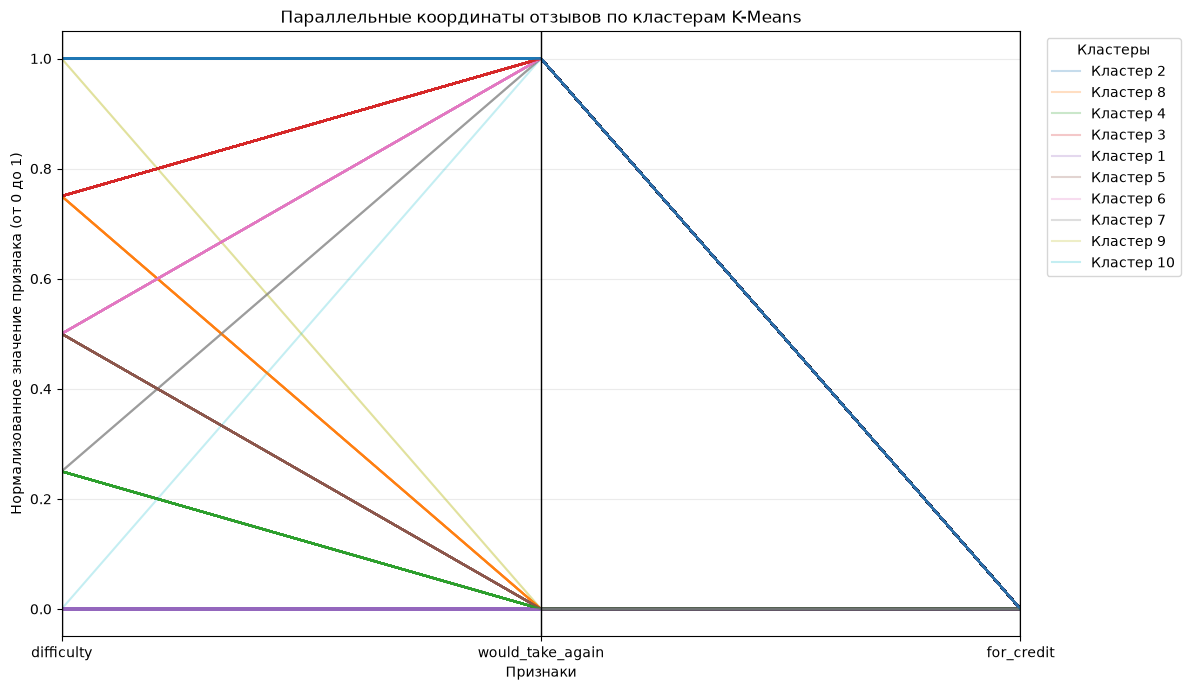

In [13]:
from pandas.plotting import parallel_coordinates
from sklearn.preprocessing import MinMaxScaler

plot_data = X[["difficulty", "would_take_again", "for_credit"]].copy().astype(float)
plot_data["cluster"] = [f"Кластер {label + 1}" for label in labels]

# Масштабируем каждый признак только для удобства визуального сравнения.
scaler_for_plot = MinMaxScaler()
plot_scaled = pd.DataFrame(
    scaler_for_plot.fit_transform(plot_data[["difficulty", "would_take_again", "for_credit"]]),
    columns=["difficulty", "would_take_again", "for_credit"],
    index=plot_data.index
)
plot_scaled["cluster"] = plot_data["cluster"].values

# Ограничим число линий, чтобы график было легче читать.
plot_sample = plot_scaled.sample(
    n=min(1000, len(plot_scaled)),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(12, 7))
parallel_coordinates(
    plot_sample,
    class_column="cluster",
    cols=["difficulty", "would_take_again", "for_credit"],
    colormap=plt.get_cmap("tab10"),
    alpha=0.25
)
plt.title("Параллельные координаты отзывов по кластерам K-Means")
plt.xlabel("Признаки")
plt.ylabel("Нормализованное значение признака (от 0 до 1)")
plt.ylim(-0.05, 1.05)
plt.grid(axis="y", alpha=0.25)
plt.legend(title="Кластеры", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()